# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [21]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu130 torchvision: 0.26.0+cu130
Local cache: /content/cs180-hw3/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [22]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [23]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [24]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels,
                    kernel_size = 3, stride = 1, padding = 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.conv(x)
        # ===== end of code ====
        # raise NotImplementedError()


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.downConv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels,
                    kernel_size = 3, stride = 2, padding = 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.downConv(x)

        # ===== end of code ====
        # raise NotImplementedError()


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.upConv = nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels,
                    kernel_size = 4, stride = 2, padding = 1),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.upConv(x)

        # ===== end of code ====
        # raise NotImplementedError()


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.flatten = nn.AvgPool2d(kernel_size = 7)

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.flatten(x)

        # ===== end of code ====
        # raise NotImplementedError()


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.unFlatten = nn.Sequential(
            nn.ConvTranspose2d(in_channels, in_channels,
                    kernel_size = 7, stride = 1, padding = 0),
            nn.BatchNorm2d(in_channels),
            nn.GELU()
        )

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.unFlatten(x)

        # ===== end of code ====
        # raise NotImplementedError()


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv1 = Conv(in_channels, out_channels)
        self.conv2 = Conv(out_channels, out_channels)

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.conv1(x)
        x = self.conv2(x)
        return x

        # ===== end of code ====
        # raise NotImplementedError()


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv1 = DownConv(in_channels, out_channels)
        self.conv2 = ConvBlock(out_channels, out_channels)

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.conv1(x)
        x = self.conv2(x)
        return x

        # ===== end of code ====
        # raise NotImplementedError()


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv1 = UpConv(in_channels, out_channels)
        self.conv2 = ConvBlock(out_channels, out_channels)

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.conv1(x)
        x = self.conv2(x)
        return x

        # ===== end of code ====
        # raise NotImplementedError()

## Implementing Unconditional UNet

In [25]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        out_channels = in_channels
        self.conv_in = ConvBlock(in_channels, num_hiddens)
        self.down_1 = DownBlock(num_hiddens, num_hiddens)
        self.down_2 = DownBlock(num_hiddens, 2*num_hiddens )
        self.flatten = Flatten()
        self.unflatten = Unflatten(2*num_hiddens)
        self.up1 = UpBlock(4*num_hiddens, num_hiddens)
        self.up2 = UpBlock(2*num_hiddens, num_hiddens)
        self.conv_out = ConvBlock(2*num_hiddens, num_hiddens)
        self.final_conv = nn.Conv2d(num_hiddens, in_channels, kernel_size=3, padding=1)


        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        x0 = self.conv_in(x)
        x1 = self.down_1(x0)
        x2 = self.down_2(x1)
        x3 = self.flatten(x2)
        x4 = self.unflatten(x3)
        x5 = self.up1(torch.cat([x4, x2], dim = 1))
        x6 = self.up2(torch.cat([x5,x1], dim=1))
        x7 = self.conv_out(torch.cat([x6,x0],dim=1))
        return self.final_conv(x7)

        # ===== end of code ====
        # raise NotImplementedError()

# Part 1.2: Using the UNet to Train a Denoiser

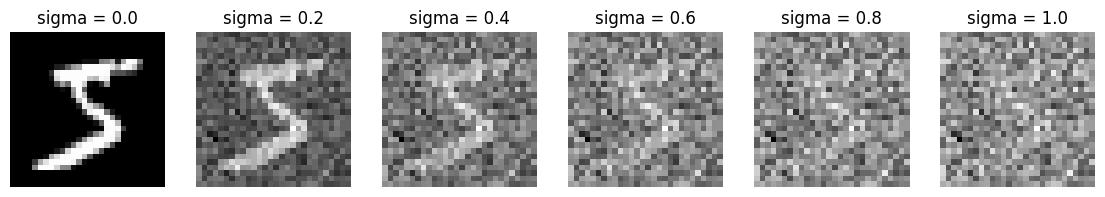

In [26]:
# Visualize images at different noisy level
# ===== your code here! ====
image = train_dataset[0][0]
noise = torch.randn_like(image)
sigmas = [0.0,0.2,.4,.6,.8,1.]
fig, axes = plt.subplots(1,6,figsize = (14,3))
for ax,sigma in zip(axes,sigmas):
  x = image + sigma * noise
  ax.imshow(x.squeeze(), cmap = "gray")
  ax.set_title(f"sigma = {sigma}")
  ax.axis("off")
plt.show()

# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [27]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

In [28]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle = True)
test_loader = DataLoader(test_dataset, batch_size = 256, shuffle = False)

In [29]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(
    in_channels=1,
    num_hiddens=hidden_dim
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)
criterion = nn.MSELoss()
# ===== end of code ====

In [30]:
# The training loops
train_losses = []
for epoch in range(num_epochs):
    for i, (images, _) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====
        images = images.to(device)
        noise = torch.randn_like(images)
        noisy_images = images + noise_level * noise

        outputs = model(noisy_images)

        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

  0%|          | 0/235 [00:00<?, ?it/s]

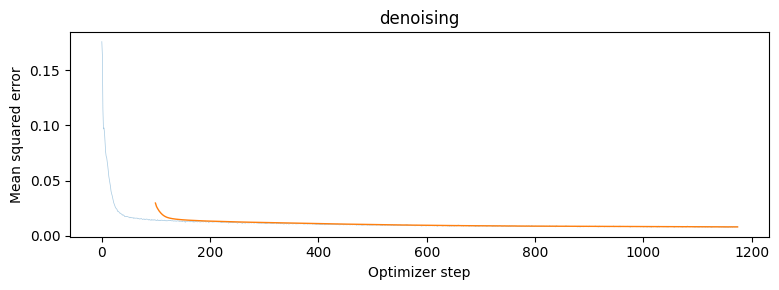

In [31]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, "denoising")
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

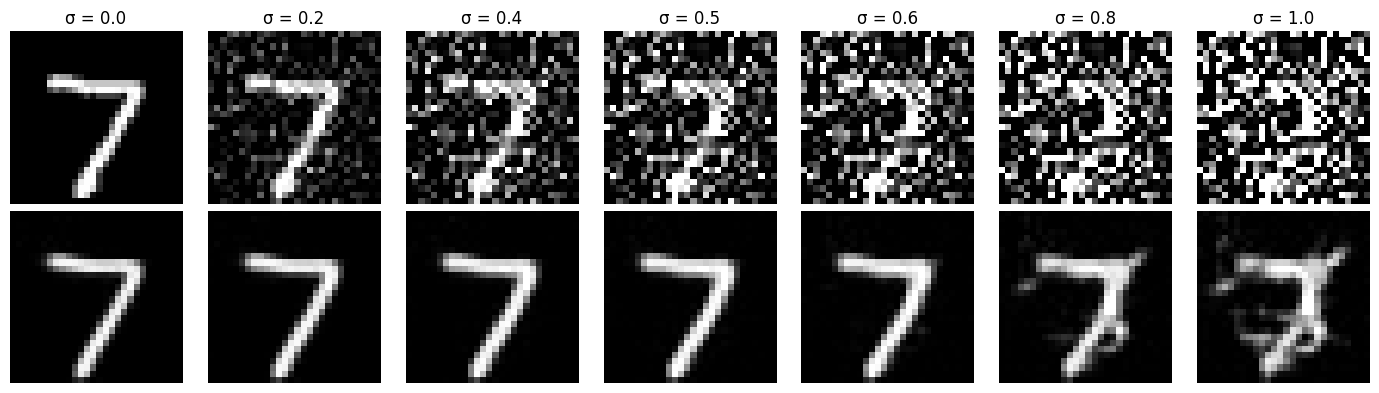

In [32]:
# Visualize OOD testing
# ===== your code here! ====

# 1.2.2 Out-of-distribution denoising

image = test_dataset[0][0].unsqueeze(0).to(device)
noise = torch.randn_like(image)
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]

model.eval()

fig, axes = plt.subplots(2, len(sigmas), figsize=(14, 4))

with torch.no_grad():
    for i, sigma in enumerate(sigmas):
        x = image + sigma * noise
        y = model(x)

        axes[0, i].imshow(
            x[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1
        )
        axes[0, i].set_title(f"σ = {sigma}")
        axes[0, i].axis("off")

        axes[1, i].imshow(
            y[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1
        )
        axes[1, i].axis("off")

axes[0, 0].set_ylabel("Noisy input")
axes[1, 0].set_ylabel("Denoised output")

plt.tight_layout()
plt.show()



# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

Epoch 1:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 1: Loss = 0.0752


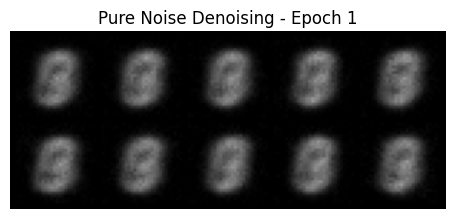

Epoch 2:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 2: Loss = 0.0676


Epoch 3:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 3: Loss = 0.0675


Epoch 4:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 4: Loss = 0.0674


Epoch 5:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 5: Loss = 0.0674


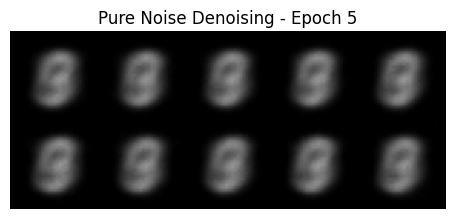

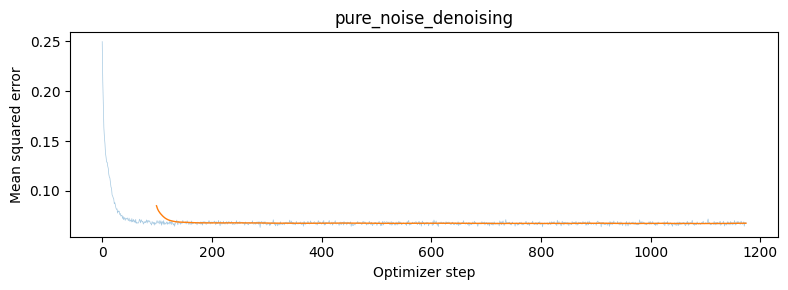

In [33]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.

# 1.2.3 Train a UNet to denoise pure Gaussian noise

from pathlib import Path
from tqdm.auto import tqdm

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

pure_noise_model = UnconditionalUNet(
    in_channels=1,
    num_hiddens=128
).to(device)

optimizer = torch.optim.Adam(
    pure_noise_model.parameters(),
    lr=1e-4
)

criterion = nn.MSELoss()
train_loader = make_loader(batch_size=256)

num_epochs = 5
losses = []

# Fixed noise so we can compare epoch 1 vs epoch 5
fixed_noise = torch.randn(10, 1, 28, 28, device=device)

for epoch in range(num_epochs):
    pure_noise_model.train()
    epoch_losses = []

    for images, labels in tqdm(
        train_loader, desc=f"Epoch {epoch + 1}"
    ):
        images = images.to(device)

        # Pure noise, independent of the clean image
        noise = torch.randn_like(images)

        # Predict a clean image from pure noise
        prediction = pure_noise_model(noise)

        loss = criterion(prediction, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        epoch_losses.append(loss.item())

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {sum(epoch_losses)/len(epoch_losses):.4f}"
    )

    # Save model weights and optimizer state
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": pure_noise_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "losses": losses
    }, checkpoint_dir / f"pure_noise_epoch_{epoch+1}.pth")

    if epoch + 1 in [1, 5]:
        pure_noise_model.eval()

        with torch.no_grad():
            generated = pure_noise_model(fixed_noise)

        show_grid(
            generated,
            f"Pure Noise Denoising - Epoch {epoch+1}",
            f"pure_noise_epoch_{epoch+1}.png",
            nrow=5
        )

# Plot complete training loss
loss_plot(losses, "pure_noise_denoising")

# raise NotImplementedError('Implement the pure-noise experiment')

In [34]:

# Inspect your trained pure-noise model from 1.2.3
m = pure_noise_model

print("Model device:", next(m.parameters()).device)

total = 0

for name, param in m.named_parameters():
    print(name, tuple(param.shape), "values:",
          param.detach().flatten()[:5].cpu().numpy())
    total += param.numel()

print("\nTotal trainable parameters:", total)


Model device: cuda:0
conv_in.conv1.conv.0.weight (128, 1, 3, 3) values: [0.02955409 0.27906984 0.02699876 0.00347169 0.00675915]
conv_in.conv1.conv.0.bias (128,) values: [ 0.29624048  0.05633469 -0.06836826  0.00705199  0.01162404]
conv_in.conv1.conv.1.weight (128,) values: [1.0004683  0.99992305 0.99955    1.0008854  0.99995935]
conv_in.conv1.conv.1.bias (128,) values: [0.00218751 0.00166137 0.00104616 0.00219501 0.00133849]
conv_in.conv2.conv.0.weight (128, 128, 3, 3) values: [ 0.01628407  0.01426652 -0.02678177  0.02447769  0.02480619]
conv_in.conv2.conv.0.bias (128,) values: [-0.02097142 -0.00243767  0.0060573  -0.0271318  -0.02389997]
conv_in.conv2.conv.1.weight (128,) values: [0.99019974 0.9930312  0.99232423 0.9925779  0.9936789 ]
conv_in.conv2.conv.1.bias (128,) values: [-0.00217641 -0.00422676 -0.00166721 -0.00387853 -0.00235891]
down_1.conv1.downConv.0.weight (128, 128, 3, 3) values: [ 0.00692562  0.02407557 -0.00697308 -0.00952715 -0.01562808]
down_1.conv1.downConv.0.bias (1

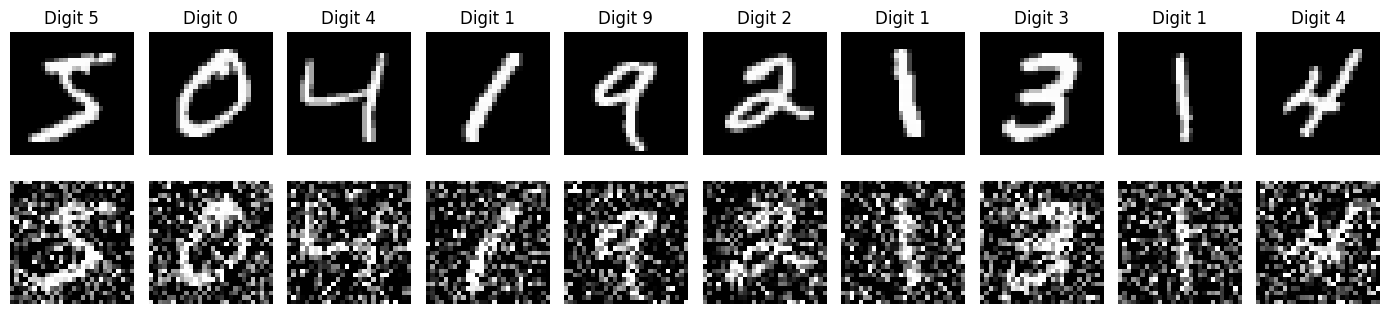

In [35]:

fig, axes = plt.subplots(2, 10, figsize=(14, 3.5))

for i in range(10):
    image, label = train_dataset[i]

    axes[0, i].imshow(image.squeeze(), cmap="gray")
    axes[0, i].set_title(f"Digit {label}")

    noise = torch.randn_like(image)
    axes[1, i].imshow(
        (image + 0.5 * noise).squeeze(),
        cmap="gray",
        vmin=0, vmax=1
    )

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [45]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.linear1 = nn.Sequential(
            nn.Linear(in_channels, out_channels),
            nn.GELU()
        )
        self.linear2 = nn.Linear(out_channels, out_channels)

        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        l1 = self.linear1(x)
        return self.linear2(l1)

        # ===== end of code ====
        # raise NotImplementedError()


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        out_channels = in_channels
        self.conv_in = ConvBlock(in_channels, num_hiddens)
        self.down_1 = DownBlock(num_hiddens, num_hiddens)
        self.down_2 = DownBlock(num_hiddens, 2*num_hiddens )
        self.flatten = Flatten()
        self.unflatten = Unflatten(2*num_hiddens)
        self.fc1_t = FCBlock(1,2*num_hiddens)
        self.fc2_t = FCBlock(1,num_hiddens)
        self.up1 = UpBlock(4*num_hiddens, num_hiddens)
        self.up2 = UpBlock(2*num_hiddens, num_hiddens)
        self.conv_out = ConvBlock(2*num_hiddens, num_hiddens)
        self.final_conv = nn.Conv2d(num_hiddens, in_channels, kernel_size=3, padding=1)


        # ===== end of code ====

    def forward(
    self,
    x: torch.Tensor,
    t: torch.Tensor
) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.float().reshape(-1, 1)
        x0 = self.conv_in(x)
        x1 = self.down_1(x0)
        x2 = self.down_2(x1)
        x3 = self.flatten(x2)
        x4 = self.unflatten(x3)
        t1 = self.fc1_t(t)
        t1 = t1[:, :, None, None]
        x4 = x4 * t1
        x5 = self.up1(torch.cat([x4, x2], dim = 1))
        t2 = self.fc2_t(t)
        t2 = t2[:, :, None, None]    # (N, D, 1, 1)
        x5 = x5 * t2
        x6 = self.up2(torch.cat([x5,x1], dim=1))
        x7 = self.conv_out(torch.cat([x6,x0],dim=1))
        return self.final_conv(x7)

        # ===== end of code ====
        # raise NotImplementedError()

## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [39]:

# New model
unet = TimeConditionalUNet(
    in_channels=1,
    num_classes=10,
    num_hiddens=64
).to(device)

# New optimizer
optimizer = torch.optim.Adam(
    unet.parameters(),
    lr=1e-2
)

# Same loss type
criterion = nn.MSELoss()

# Scheduler
num_epochs = 10
scheduler = torch.optim.lr_scheduler.ExponentialLR(
    optimizer,
    gamma=0.1 ** (1 / num_epochs)
)

# New dataloader with batch size 64
train_loader = make_loader(batch_size=64)


In [41]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    N = x_1.shape[0]

    x_0 = torch.randn_like(x_1)

    t = torch.randint(
        0, num_ts, (N,), device = x_1.device
    ).float() / num_ts

    t_image = t.view(N,1,1,1)

    x_t = (1 - t_image) * x_0 + t_image * x_1

    target_velocity = x_1 - x_0

    predicted_velocity = unet(x_t,t)

    loss = F.mse_loss(
        predicted_velocity,
        target_velocity
    )
    return loss

    # ===== end of code ====
    # raise NotImplementedError()

In [42]:

@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:

    unet.eval()

    device = next(unet.parameters()).device

    # Reproducible noise without changing global RNG
    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    # Generate 10 random images
    x = torch.randn(
        10, 1, img_wh[0], img_wh[1],
        device=device,
        generator=generator
    )

    dt = 1.0 / num_ts

    # Euler sampling: t = 0 -> t = 1
    for i in range(num_ts):

        t = torch.full(
            (x.shape[0],),
            i / num_ts,
            device=device
        )

        # Predict velocity at current timestep
        velocity = unet(x, t)

        # Update image
        x = x + dt * velocity

    return x


    # ===== end of code ====
    # raise NotImplementedError()

In [43]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

Epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 1/10 | Loss: 0.1658 | LR: 0.010000
Saved checkpoint: epoch 1


Epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2/10 | Loss: 0.1125 | LR: 0.007943


Epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

Epoch 8/10 | Loss: 0.0899 | LR: 0.001995


Epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 9/10 | Loss: 0.0890 | LR: 0.001585


Epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 10/10 | Loss: 0.0882 | LR: 0.001259
Saved checkpoint: epoch 10


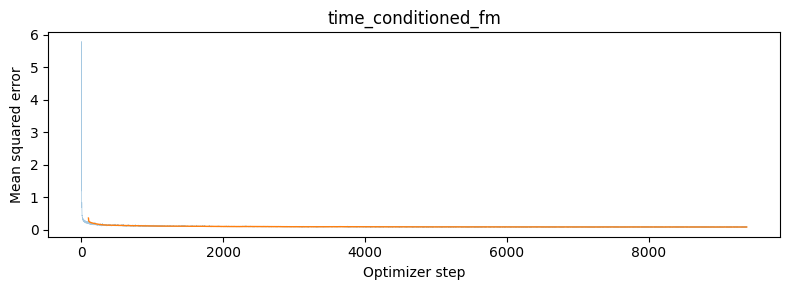

In [46]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====

from pathlib import Path
from tqdm.auto import tqdm
import torch

# Hyperparameters
num_epochs = 10
batch_size = 64
learning_rate = 1e-2
num_ts = 50

# DataLoader
train_loader = make_loader(batch_size=batch_size)

# New time-conditioned UNet
unet = TimeConditionalUNet(
    in_channels=1,
    num_classes=10,
    num_hiddens=64
).to(device)

# Flow matching wrapper
fm = TimeConditionalFM(
    unet=unet,
    num_ts=num_ts,
    img_hw=(28, 28)
).to(device)

# Optimizer
optimizer = torch.optim.Adam(
    fm.parameters(),
    lr=learning_rate
)

# Exponential learning rate scheduler
scheduler = torch.optim.lr_scheduler.ExponentialLR(
    optimizer,
    gamma=0.1 ** (1 / num_epochs)
)

# Checkpoint directory
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

train_losses = []

# Training loop
for epoch in range(num_epochs):
    fm.train()
    epoch_losses = []

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{num_epochs}"
    ):
        images = images.to(device)

        # Flow matching forward pass returns MSE loss
        loss = fm(images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())
        epoch_losses.append(loss.item())

    avg_loss = sum(epoch_losses) / len(epoch_losses)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    # Update learning rate after each epoch
    scheduler.step()

    # Save selected checkpoints
    if epoch + 1 in [1, 5, 10]:
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": fm.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "losses": train_losses,
        }, checkpoint_dir / f"time_fm_epoch_{epoch+1}.pth")

        print(f"Saved checkpoint: epoch {epoch+1}")

# Plot training loss
loss_plot(train_losses, "time_conditioned_fm")


# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

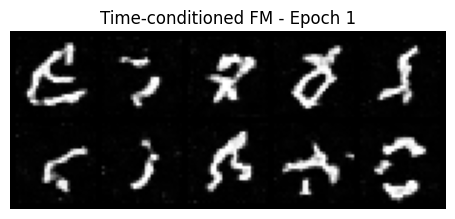

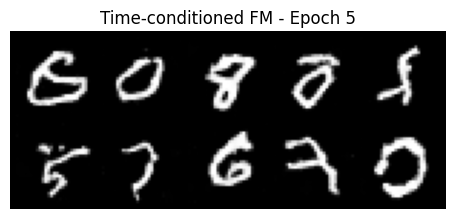

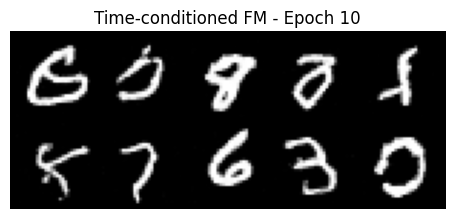

In [47]:
# Sampling from the UNet
# ===== your code here! ====

from pathlib import Path
import torch

checkpoint_dir = Path("checkpoints")

for epoch in [1, 5, 10]:

    checkpoint_path = (
        checkpoint_dir / f"time_fm_epoch_{epoch}.pth"
    )

    # Load saved checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    # Create fresh model with same architecture
    unet_sample = TimeConditionalUNet(
        in_channels=1,
        num_classes=10,
        num_hiddens=64
    ).to(device)

    fm_sample_model = TimeConditionalFM(
        unet=unet_sample,
        num_ts=50,
        img_hw=(28, 28)
    ).to(device)

    # Restore learned weights
    fm_sample_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    fm_sample_model.eval()

    # Generate 10 images with the same initial noise
    generated = fm_sample_model.sample(
        img_wh=(28, 28),
        seed=42
    )

    show_grid(
        generated,
        f"Time-conditioned FM - Epoch {epoch}",
        f"time_fm_epoch_{epoch}_samples.png",
        nrow=5
    )


# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [48]:

class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()

        D = num_hiddens
        self.in_channels = in_channels
        self.num_classes = num_classes

        # Encoder
        self.conv_in = ConvBlock(in_channels, D)
        self.down_1 = DownBlock(D, D)
        self.down_2 = DownBlock(D, 2 * D)

        # Bottleneck
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * D)

        # Time embeddings
        self.fc1_t = FCBlock(1, 2 * D)
        self.fc2_t = FCBlock(1, D)

        # Class embeddings
        self.fc1_c = FCBlock(num_classes, 2 * D)
        self.fc2_c = FCBlock(num_classes, D)

        # Decoder
        self.up1 = UpBlock(4 * D, D)
        self.up2 = UpBlock(2 * D, D)

        self.conv_out = ConvBlock(2 * D, D)
        self.final_conv = nn.Conv2d(
            D, in_channels, kernel_size=3, padding=1
        )

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:

        assert x.shape[-2:] == (28, 28)

        N = x.shape[0]

        # Time: (N,) -> (N, 1)
        t = t.float().reshape(N, 1)

        # Class labels -> one-hot encoding
        c = F.one_hot(
            c.long(), num_classes=self.num_classes
        ).float()

        # Drop class conditioning when mask = 0
        if mask is not None:
            c = c * mask.reshape(N, 1).float()

        # Encoder
        x0 = self.conv_in(x)       # (N, D, 28, 28)
        x1 = self.down_1(x0)       # (N, D, 14, 14)
        x2 = self.down_2(x1)       # (N, 2D, 7, 7)

        # Bottleneck
        x3 = self.flatten(x2)      # (N, 2D, 1, 1)
        x4 = self.unflatten(x3)    # (N, 2D, 7, 7)

        # First conditioning
        t1 = self.fc1_t(t)[:, :, None, None]
        c1 = self.fc1_c(c)[:, :, None, None]

        x4 = c1 * x4 + t1

        # First upsampling
        x5 = self.up1(
            torch.cat([x4, x2], dim=1)
        )

        # Second conditioning
        t2 = self.fc2_t(t)[:, :, None, None]
        c2 = self.fc2_c(c)[:, :, None, None]

        x5 = c2 * x5 + t2

        # Second upsampling
        x6 = self.up2(
            torch.cat([x5, x1], dim=1)
        )

        # Output
        x7 = self.conv_out(
            torch.cat([x6, x0], dim=1)
        )

        return self.final_conv(x7)


In [49]:

def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:

    unet.train()

    N = x_1.shape[0]

    # Random Gaussian noise
    x_0 = torch.randn_like(x_1)

    # Random timesteps
    t = torch.randint(
        0, num_ts, (N,), device=x_1.device
    ).float() / num_ts

    t_image = t.view(N, 1, 1, 1)

    # Interpolate between noise and clean image
    x_t = (1 - t_image) * x_0 + t_image * x_1

    # Ground-truth velocity
    target_velocity = x_1 - x_0

    # Classifier-free guidance dropout
    # 1 = keep class, 0 = remove class
    mask = (
        torch.rand(N, device=x_1.device) > p_uncond
    ).float()

    # Predict velocity
    predicted_velocity = unet(
        x_t, c, t, mask=mask
    )

    # MSE loss
    loss = F.mse_loss(
        predicted_velocity,
        target_velocity
    )

    return loss


In [50]:

@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
):

    unet.eval()

    device = next(unet.parameters()).device
    c = c.to(device).long()

    N = c.shape[0]

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    # Start from Gaussian noise
    x = torch.randn(
        N, unet.in_channels,
        img_wh[0], img_wh[1],
        device=device,
        generator=generator
    )

    dt = 1.0 / num_ts

    # Save intermediate results for animation
    caches = []

    for i in range(num_ts):

        t = torch.full(
            (N,),
            i / num_ts,
            device=device
        )

        # Conditional prediction
        v_cond = unet(
            x, c, t,
            mask=torch.ones(N, device=device)
        )

        # Unconditional prediction
        v_uncond = unet(
            x, c, t,
            mask=torch.zeros(N, device=device)
        )

        # Classifier-free guidance
        velocity = v_uncond + guidance_scale * (
            v_cond - v_uncond
        )

        # Euler integration
        x = x + dt * velocity

        # Save selected intermediate images
        if i % max(1, num_ts // 10) == 0:
            caches.append(x.detach().clone())

    caches.append(x.detach().clone())

    caches = torch.stack(caches, dim=1)

    return x, caches


In [51]:

class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor
    ) -> torch.Tensor:

        return class_fm_forward(
            self.unet,
            x,
            c,
            self.p_uncond,
            self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet,
            c,
            img_wh,
            self.num_ts,
            guidance_scale,
            seed
        )


In [52]:

# Initialize model
class_unet = ClassConditionalUNet(
    in_channels=1,
    num_classes=10,
    num_hiddens=64
).to(device)

class_fm = ClassConditionalFM(
    unet=class_unet,
    num_ts=300,
    p_uncond=0.1
).to(device)

# Test training forward pass
x = torch.randn(4, 1, 28, 28, device=device)
c = torch.tensor([0, 1, 2, 3], device=device)

loss = class_fm(x, c)

print("Loss:", loss.item())

# Verify gradients can be calculated
loss.backward()

# Test sampling
generated, caches = class_fm.sample(
    c=c,
    img_wh=(28, 28),
    guidance_scale=5.0,
    seed=42
)

print("Generated shape:", generated.shape)
print("Cache shape:", caches.shape)

assert generated.shape == (4, 1, 28, 28)
print("All tests passed!")


Loss: 2.0836105346679688
Generated shape: torch.Size([4, 1, 28, 28])
Cache shape: torch.Size([4, 11, 1, 28, 28])
All tests passed!


# Part 2.5 Training the Class-conditioned UNet

class_fm: Epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm | Epoch 1 | Loss: 0.1599 | LR: 0.007943
Saved: checkpoints/class_fm_epoch_1.pth


class_fm: Epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm | Epoch 2 | Loss: 0.1105 | LR: 0.006310


class_fm: Epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

class_fm | Epoch 8 | Loss: 0.0853 | LR: 0.001585


class_fm: Epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm | Epoch 9 | Loss: 0.0840 | LR: 0.001259


class_fm: Epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm | Epoch 10 | Loss: 0.0830 | LR: 0.001000
Saved: checkpoints/class_fm_epoch_10.pth


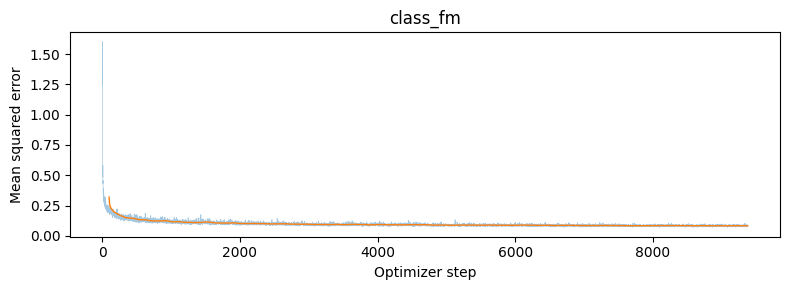

class_fm_no_scheduler: Epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm_no_scheduler | Epoch 1 | Loss: 0.1320 | LR: 0.001000
Saved: checkpoints/class_fm_no_scheduler_epoch_1.pth


class_fm_no_scheduler: Epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm_no_scheduler | Epoch 2 | Loss: 0.0993 | LR: 0.001000


class_fm_no_scheduler: Epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

class_fm_no_scheduler | Epoch 8 | Loss: 0.0842 | LR: 0.001000


class_fm_no_scheduler: Epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm_no_scheduler | Epoch 9 | Loss: 0.0840 | LR: 0.001000


class_fm_no_scheduler: Epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

class_fm_no_scheduler | Epoch 10 | Loss: 0.0829 | LR: 0.001000
Saved: checkpoints/class_fm_no_scheduler_epoch_10.pth


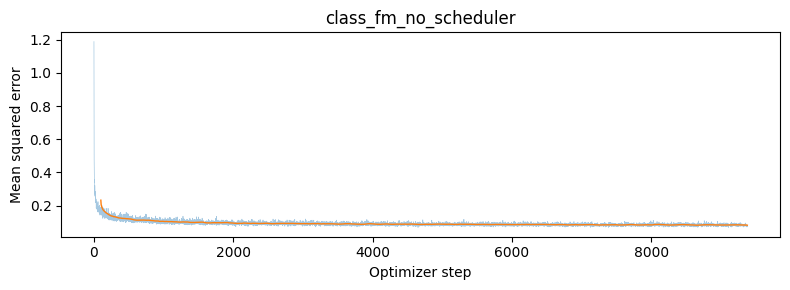

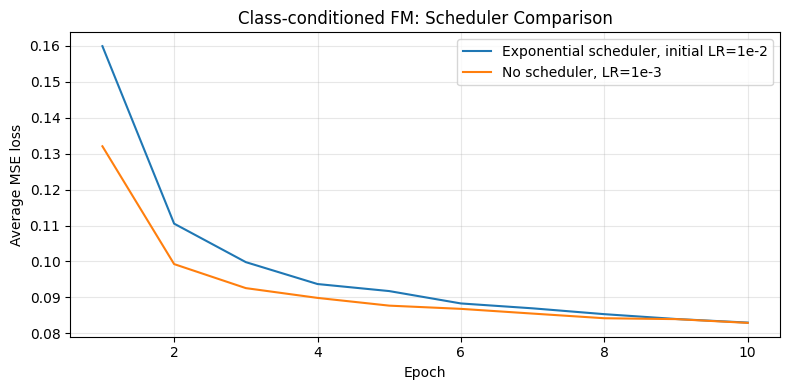

In [53]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.
# raise NotImplementedError('Implement both class-conditioned experiments')


from pathlib import Path
from tqdm.auto import tqdm
import torch
import matplotlib.pyplot as plt

# Hyperparameters
num_epochs = 10
batch_size = 64
learning_rate = 1e-2
num_ts = 300
p_uncond = 0.1

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Use the existing MNIST dataset
train_loader = make_loader(batch_size=batch_size)

def train_class_fm(
    use_scheduler=True,
    lr=1e-2,
    run_name="class_fm"
):
    # Fresh model for each experiment
    unet = ClassConditionalUNet(
        in_channels=1,
        num_classes=10,
        num_hiddens=64
    ).to(device)

    fm = ClassConditionalFM(
        unet=unet,
        num_ts=num_ts,
        p_uncond=p_uncond
    ).to(device)

    optimizer = torch.optim.Adam(
        fm.parameters(),
        lr=lr
    )

    scheduler = (
        torch.optim.lr_scheduler.ExponentialLR(
            optimizer,
            gamma=0.1 ** (1 / num_epochs)
        )
        if use_scheduler else None
    )

    all_losses = []
    epoch_losses = []

    for epoch in range(num_epochs):
        fm.train()
        batch_losses = []

        for images, labels in tqdm(
            train_loader,
            desc=f"{run_name}: Epoch {epoch+1}/{num_epochs}"
        ):
            images = images.to(device)
            labels = labels.to(device)

            # Compute class-conditioned FM loss
            loss = fm(images, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())
            all_losses.append(loss.item())

        avg_loss = sum(batch_losses) / len(batch_losses)
        epoch_losses.append(avg_loss)

        if scheduler is not None:
            scheduler.step()

        print(
            f"{run_name} | Epoch {epoch+1} | "
            f"Loss: {avg_loss:.4f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

        # Save at epochs 1, 5, 10
        if epoch + 1 in [1, 5, 10]:
            path = (
                checkpoint_dir /
                f"{run_name}_epoch_{epoch+1}.pth"
            )

            torch.save({
                "epoch": epoch + 1,
                "model_state_dict": fm.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": (
                    scheduler.state_dict()
                    if scheduler is not None else None
                ),
                "losses": all_losses,
                "epoch_losses": epoch_losses,
                "lr": lr,
                "num_ts": num_ts,
                "p_uncond": p_uncond,
                "use_scheduler": use_scheduler
            }, path)

            print(f"Saved: {path}")

    return fm, all_losses, epoch_losses


# Experiment 1: Exponential learning-rate scheduler
fm_class, class_losses, class_epoch_losses = train_class_fm(
    use_scheduler=True,
    lr=1e-2,
    run_name="class_fm"
)

loss_plot(class_losses, "class_fm")

# Experiment 2: No learning-rate scheduler
# Keep the rate lower because it no longer decays.
fm_no_scheduler, no_sched_losses, no_sched_epoch_losses = (
    train_class_fm(
        use_scheduler=False,
        lr=1e-3,
        run_name="class_fm_no_scheduler"
    )
)

loss_plot(no_sched_losses, "class_fm_no_scheduler")

# Compare training loss
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, 11),
    class_epoch_losses,
    label="Exponential scheduler, initial LR=1e-2"
)
plt.plot(
    range(1, 11),
    no_sched_epoch_losses,
    label="No scheduler, LR=1e-3"
)

plt.xlabel("Epoch")
plt.ylabel("Average MSE loss")
plt.title("Class-conditioned FM: Scheduler Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUT / "class_fm_scheduler_comparison.png",
    dpi=150
)
plt.show()


# Part 2.6: Sampling from the Class-conditioned UNet

Number of images: 40
Epoch 1: torch.Size([40, 1, 28, 28])


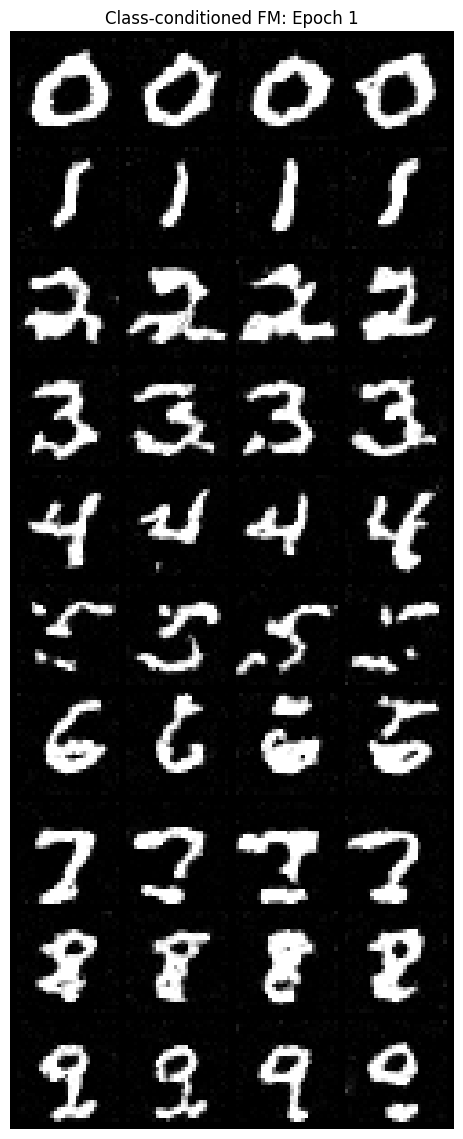

Epoch 5: torch.Size([40, 1, 28, 28])


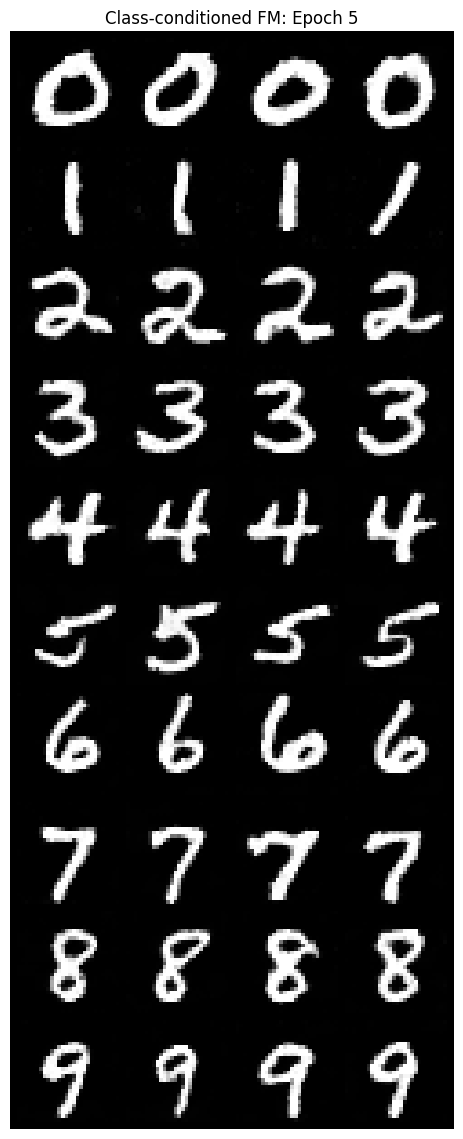

Epoch 10: torch.Size([40, 1, 28, 28])


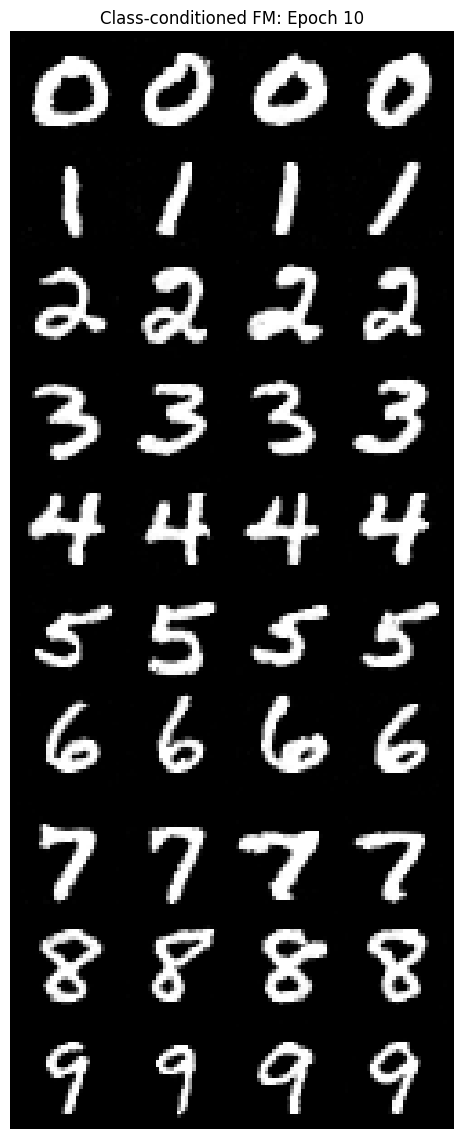

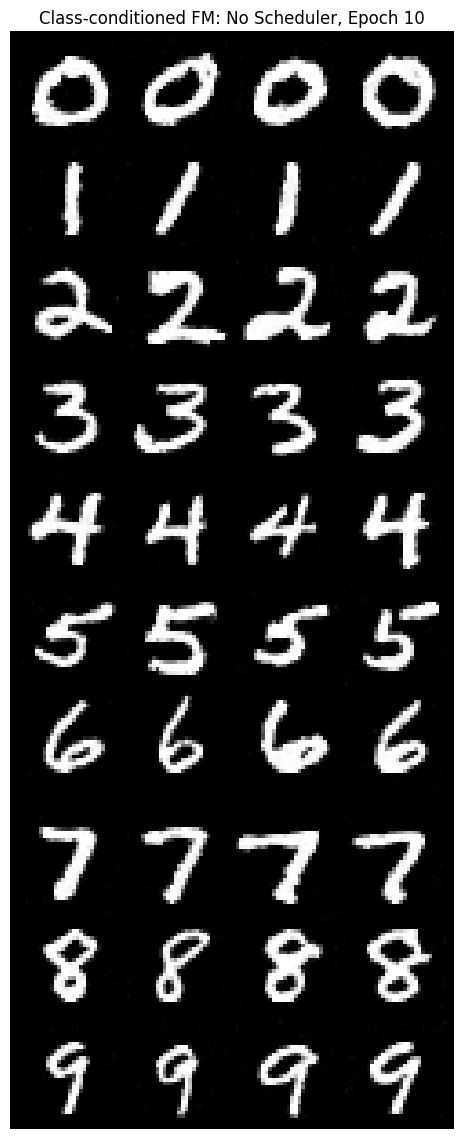

In [54]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.
# raise NotImplementedError('Implement sampling and comparison')


# Part 2.6: Class-conditioned sampling

from pathlib import Path
import torch
import matplotlib.pyplot as plt

checkpoint_dir = Path("checkpoints")

# 4 images of each digit: 0,0,0,0,1,1,1,1,...,9,9,9,9
labels = torch.arange(10).repeat_interleave(4).to(device)

print("Number of images:", len(labels))

def load_class_fm(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    unet = ClassConditionalUNet(
        in_channels=1,
        num_classes=10,
        num_hiddens=64
    ).to(device)

    fm = ClassConditionalFM(
        unet=unet,
        num_ts=checkpoint.get("num_ts", 300),
        p_uncond=checkpoint.get("p_uncond", 0.1)
    ).to(device)

    fm.load_state_dict(
        checkpoint["model_state_dict"]
    )
    fm.eval()

    return fm


# 1. Sample epochs 1, 5 and 10
for epoch in [1, 5, 10]:

    path = checkpoint_dir / f"class_fm_epoch_{epoch}.pth"

    fm_sample = load_class_fm(path)

    generated, caches = fm_sample.sample(
        c=labels,
        img_wh=(28, 28),
        guidance_scale=5.0,
        seed=42
    )

    print(f"Epoch {epoch}: {generated.shape}")

    show_grid(
        generated,
        f"Class-conditioned FM: Epoch {epoch}",
        f"class_fm_epoch_{epoch}_samples.png",
        nrow=4
    )


# 2. Sample model without scheduler
path = checkpoint_dir / "class_fm_no_scheduler_epoch_10.pth"

fm_sample_no_sched = load_class_fm(path)

generated_no_sched, caches_no_sched = (
    fm_sample_no_sched.sample(
        c=labels,
        img_wh=(28, 28),
        guidance_scale=5.0,
        seed=42
    )
)

show_grid(
    generated_no_sched,
    "Class-conditioned FM: No Scheduler, Epoch 10",
    "class_fm_no_scheduler_samples.png",
    nrow=4
)


Resuming after epoch: 10
Current LR: 0.001


Epoch 11/20:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 11: Loss = 0.0878, LR = 0.001000


Epoch 12/20:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 12: Loss = 0.0872, LR = 0.000794


...

Epoch 18: Loss = 0.0856, LR = 0.000200


Epoch 19/20:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 19: Loss = 0.0854, LR = 0.000158


Epoch 20/20:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 20: Loss = 0.0854, LR = 0.000126
Saved: checkpoints/time_fm_epoch_20.pth


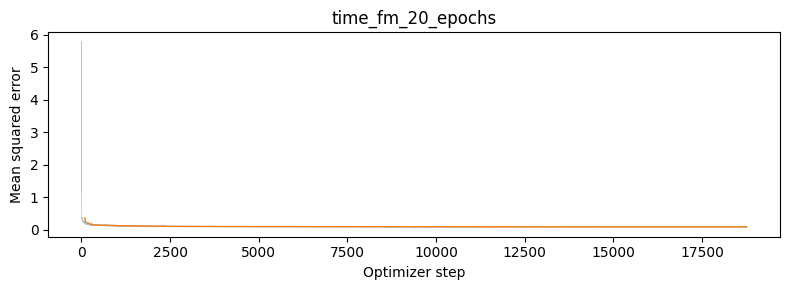

In [55]:

# Part 3: Bells & Whistles
# Extend time-only flow matching from 10 to 20 epochs

from pathlib import Path
from tqdm.auto import tqdm
import torch
import matplotlib.pyplot as plt

checkpoint_dir = Path("checkpoints")
base_path = checkpoint_dir / "time_fm_epoch_10.pth"

assert base_path.exists(), f"Missing: {base_path}"

# 1. Reconstruct the same time-only architecture
better_unet = TimeConditionalUNet(
    in_channels=1,
    num_classes=10,
    num_hiddens=64
).to(device)

better_fm = TimeConditionalFM(
    unet=better_unet,
    num_ts=50,
    img_hw=(28, 28)
).to(device)

# 2. Create optimizer
better_optimizer = torch.optim.Adam(
    better_fm.parameters(),
    lr=1e-2
)

# Same scheduler configuration as original training
better_scheduler = (
    torch.optim.lr_scheduler.ExponentialLR(
        better_optimizer,
        gamma=0.1 ** (1 / 10)
    )
)

# 3. Restore previous checkpoint
checkpoint = torch.load(
    base_path,
    map_location=device,
    weights_only=True
)

better_fm.load_state_dict(
    checkpoint["model_state_dict"]
)

better_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

better_scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

all_losses = list(checkpoint["losses"])
start_epoch = checkpoint["epoch"]

print("Resuming after epoch:", start_epoch)
print(
    "Current LR:",
    better_optimizer.param_groups[0]["lr"]
)

# 4. Dataloader
better_loader = make_loader(batch_size=64)

# 5. Train for another 10 epochs
additional_epochs = 10

for epoch in range(start_epoch, start_epoch + additional_epochs):
    better_fm.train()
    epoch_losses = []

    for images, labels in tqdm(
        better_loader,
        desc=f"Epoch {epoch+1}/20"
    ):
        images = images.to(device)

        # Flow matching loss
        loss = better_fm(images)

        better_optimizer.zero_grad()
        loss.backward()
        better_optimizer.step()

        epoch_losses.append(loss.item())
        all_losses.append(loss.item())

    avg_loss = sum(epoch_losses) / len(epoch_losses)

    print(
        f"Epoch {epoch+1}: "
        f"Loss = {avg_loss:.4f}, "
        f"LR = {better_optimizer.param_groups[0]['lr']:.6f}"
    )

    better_scheduler.step()

    # Save additional checkpoints
    if epoch + 1 in [15, 20]:
        save_path = (
            checkpoint_dir / f"time_fm_epoch_{epoch+1}.pth"
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": better_fm.state_dict(),
            "optimizer_state_dict": better_optimizer.state_dict(),
            "scheduler_state_dict": better_scheduler.state_dict(),
            "losses": all_losses
        }, save_path)

        print("Saved:", save_path)

# 6. Plot all 20 epochs
loss_plot(
    all_losses,
    "time_fm_20_epochs"
)


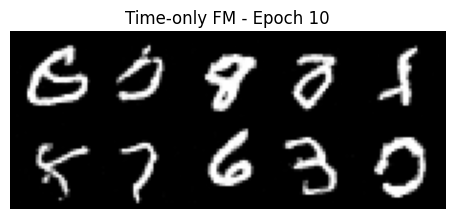

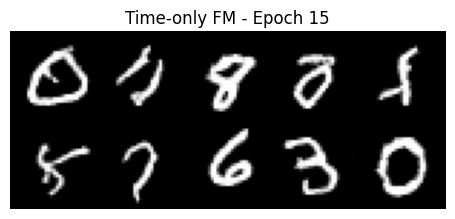

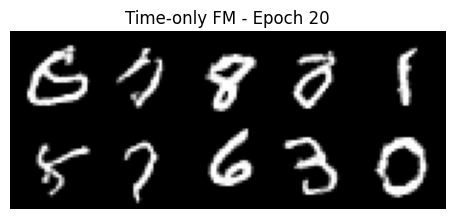

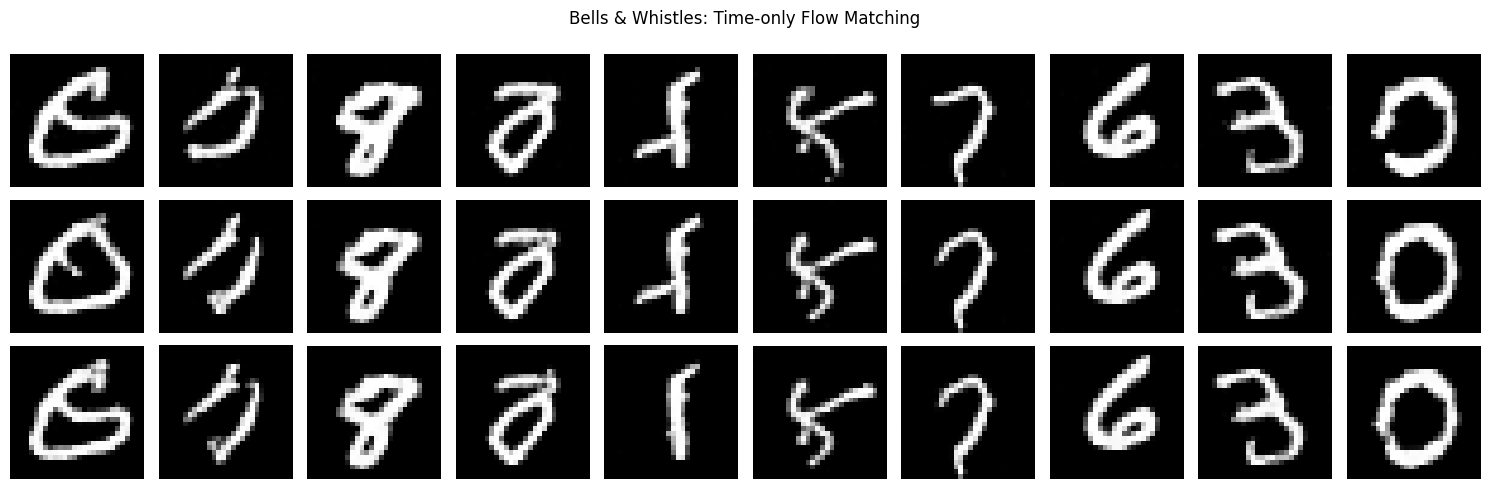

In [56]:

# Part 3: Compare time-only models

from pathlib import Path
import torch

checkpoint_dir = Path("checkpoints")

def load_time_fm(path):
    ckpt = torch.load(
        path,
        map_location=device,
        weights_only=True
    )

    unet = TimeConditionalUNet(
        in_channels=1,
        num_classes=10,
        num_hiddens=64
    ).to(device)

    model = TimeConditionalFM(
        unet=unet,
        num_ts=50,
        img_hw=(28, 28)
    ).to(device)

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()
    return model


samples_by_epoch = {}

for epoch in [10, 15, 20]:
    path = checkpoint_dir / f"time_fm_epoch_{epoch}.pth"

    model = load_time_fm(path)

    with torch.inference_mode():
        samples = model.sample(
            img_wh=(28, 28),
            seed=42
        )

    samples_by_epoch[epoch] = samples.detach().cpu()

    show_grid(
        samples,
        f"Time-only FM - Epoch {epoch}",
        f"bells_time_epoch_{epoch}.png",
        nrow=5
    )


# Side-by-side comparison using the SAME 10 noise seeds
fig, axes = plt.subplots(3, 10, figsize=(15, 5))

for row, epoch in enumerate([10, 15, 20]):
    images = samples_by_epoch[epoch]

    for col in range(10):
        axes[row, col].imshow(
            images[col, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"Epoch {epoch}",
        fontsize=11
    )

plt.suptitle(
    "Bells & Whistles: Time-only Flow Matching"
)
plt.tight_layout()
plt.savefig(
    OUT / "bells_time_comparison.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
